# Prueba de acceso a datos con Google Earth Engine (Python, Colab)

Notebook de prueba para evaluar el flujo con GEE en el environment `1geo20`.

1. Autenticación y conexión
2. Producto de cobertura (ESA WorldCover) sobre una área dada
3. Sentinel-2 SR y cálculo de NDVI
4. Integración, en local y en el servidor



## Bloque 1. Conexión

In [ ]:
!pip install -q rioxarray

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 1.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 8.8 MB/s eta 0:00:00


In [ ]:

import ee
import requests
import numpy as np
import matplotlib.pyplot as plt
import rioxarray
from rasterio.enums import Resampling


In [ ]:
# 1. Autenticación
ee.Authenticate(auth_mode='notebook')



To authorize access needed by Earth Engine, open the following URL in a web browser and follow the instructions. If the web browser does not start automatically, please manually browse the URL below.

    https://code.earthengine.google.com/client-auth?scopes=https%3A//www.googleapis.com/auth/earthengine%20https%3A//www.googleapis.com/auth/cloud-platform%20https%3A//www.googleapis.com/auth/drive%20https%3A//www.googleapis.com/auth/devstorage.full_control&request_id=B5w2wn8btgainH7wYyQZiastxKCsjtg6pwy1wtT5QXo&tc=wSs0-XfaqEzAPEn0ehaEnyBAxT005l66DozP4_8xgaw&cc=OrQnJfQLYWX84Lk1FDwySCzRvygGmUV3CRNU7rn3BjI

The authorization workflow will generate a code, which you should paste in the box below.
Enter verification code: 4/1AXlqoi53XorBdeVdoMpnnwDQA0aJA6V6Iy7eXaVrXtDWm7nmhxeGpPuqYyU

Successfully saved authorization token.


In [ ]:
PROJECT_ID = 'camilo-geocomputacion'   # reemplazar por el Project ID
ee.Initialize(project=PROJECT_ID)

In [ ]:
# lon_min, lat_min, lon_max, lat_max
BBOX = [-69.95, -12.908, -69.93, -12.895]
region = ee.Geometry.Rectangle(BBOX)

print("Conexión exitosa:", ee.String("Google Earth Engine activo").getInfo())

Conexión exitosa: Google Earth Engine activo


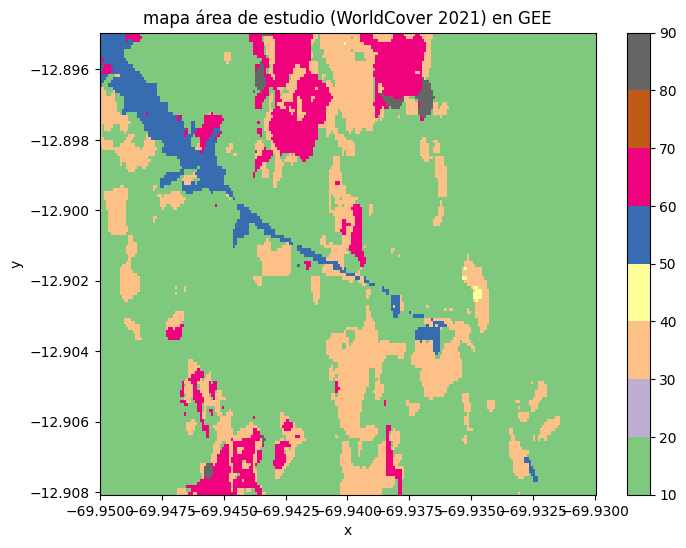

In [ ]:
wc.plot(cmap="Accent",figsize=(8, 6))
plt.title("Área de estudio en GEE (WorldCover 2021)")
plt.show()

 10  bosque amazonico      75.9 %
 30  zona talada           13.7 %
 40  Cultivos               0.1 %
 50  Urbano                 3.6 %
 60  Minería(Suelo desnudo)   6.2 %
 80  Agua                   0.5 %
 90  indeterminado          0.0 %


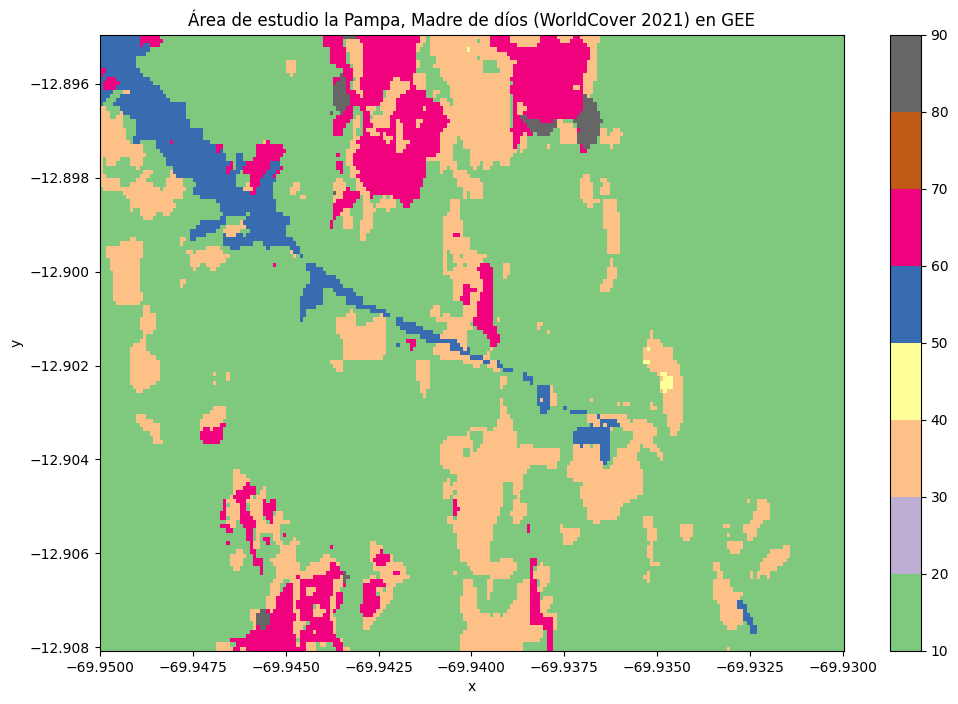

In [ ]:
CLASES = {
    10: "bosque amazonico", 20: "Arbustos", 30: "zona talada", 40: "Cultivos", 50: "Urbano",
    60: "Minería(Suelo desnudo)", 70: "Nieve/hielo", 80: "Agua", 90: "indeterminado",
    95: "Manglar", 100: "Musgo/líquenes",
}

codigos, cuentas = np.unique(wc.values, return_counts=True)
for cod, k in zip(codigos, cuentas):
    print(f"{cod:>3}  {CLASES.get(int(cod), '?'):<20} {100 * k / cuentas.sum():5.1f} %")

wc.plot(cmap="Accent",figsize=(12, 8))
plt.title("Área de estudio la Pampa, Madre de díos (WorldCover 2021) en GEE")
plt.show()

## Bloque 2. ESA WorldCover

In [ ]:
def descargar(img, nombre, escala):
    """Descarga el recorte de una imagen de GEE como GeoTIFF y lo abre con rioxarray."""
    url = img.getDownloadURL({
        "region": region,
        "scale": escala,
        "crs": "EPSG:4326",
        "format": "GEO_TIFF",
    })
    r = requests.get(url, timeout=300)
    r.raise_for_status()
    with open(nombre, "wb") as f:
        f.write(r.content)
    print(nombre, f"{len(r.content) / 1e6:.1f} MB")
    return rioxarray.open_rasterio(nombre).squeeze("band", drop=True)

In [ ]:
%%time
wc_img = ee.ImageCollection("ESA/WorldCover/v200").first().select("Map")
wc = descargar(wc_img, "worldcover_gee.tif", 10)
print(wc.rio.crs, wc.rio.resolution(), wc.shape)

worldcover_gee.tif 0.0 MB
EPSG:4326 (8.983152841195215e-05, -8.983152841195215e-05) (146, 223)
CPU times: user 48.5 ms, sys: 8.87 ms, total: 57.4 ms
Wall time: 884 ms


 10  Árboles               75.9 %
 30  Pastizal              13.7 %
 40  Cultivos               0.1 %
 50  Urbano                 3.6 %
 60  Suelo desnudo/raro     6.2 %
 80  Agua                   0.5 %
 90  Humedal herbáceo       0.0 %


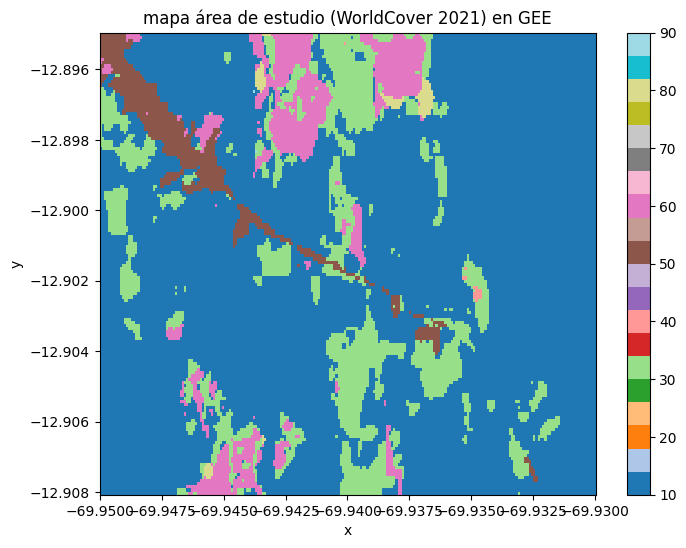

In [ ]:
CLASES = {
    10: "Árboles", 20: "Arbustos", 30: "Pastizal", 40: "Cultivos", 50: "Urbano",
    60: "Suelo desnudo/raro", 70: "Nieve/hielo", 80: "Agua", 90: "Humedal herbáceo",
    95: "Manglar", 100: "Musgo/líquenes",
}

codigos, cuentas = np.unique(wc.values, return_counts=True)
for cod, k in zip(codigos, cuentas):
    print(f"{cod:>3}  {CLASES.get(int(cod), '?'):<20} {100 * k / cuentas.sum():5.1f} %")

wc.plot(cmap="tab20", figsize=(8, 6))
plt.title("mapa área de estudio (WorldCover 2021) en GEE")
plt.show()

## Bloque 3. Sentinel-2 SR y NDVI

In [ ]:
coleccion = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(region)
    .filterDate("2025-07-01", "2025-09-30")
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20))
    .filter(ee.Filter.contains(leftField=".geo", rightValue=region))
)
n = coleccion.size().getInfo()
assert n > 0, "Ninguna escena cubre el área completo; amplía las fechas o el umbral de nubes"
print(n, "escenas")

escena = coleccion.sort("CLOUDY_PIXEL_PERCENTAGE").first()
print(escena.get("system:index").getInfo(), escena.get("CLOUDY_PIXEL_PERCENTAGE").getInfo(), "% nubes")

11 escenas
20250927T144751_20250927T144745_T19LCF 5.418421 % nubes


In [ ]:
%%time
# La colección HARMONIZED ya compensa el offset de la línea base 04.00
ndvi_img = escena.normalizedDifference(["B8", "B4"]).rename("NDVI") #operación del NDVI
ndvi = descargar(ndvi_img, "ndvi_gee.tif", 10)
print(ndvi.shape, float(ndvi.min()), float(ndvi.max()))

ndvi_gee.tif 0.1 MB
(146, 223) -0.37811899185180664 0.8828049898147583
CPU times: user 23.8 ms, sys: 2.74 ms, total: 26.6 ms
Wall time: 1.47 s


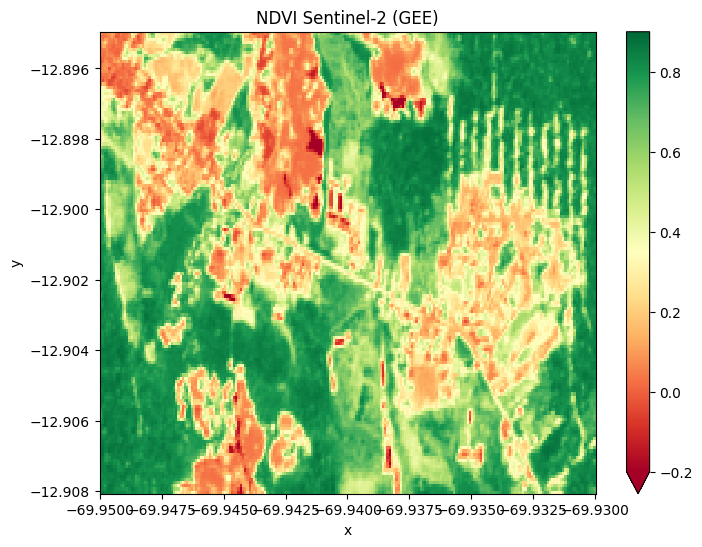

In [ ]:
ndvi.plot(cmap="RdYlGn", vmin=-0.2, vmax=0.9, figsize=(8, 6))
plt.title("NDVI Sentinel-2 (GEE)")
plt.show()

ndvi_compuesto_gee.tif 0.4 MB


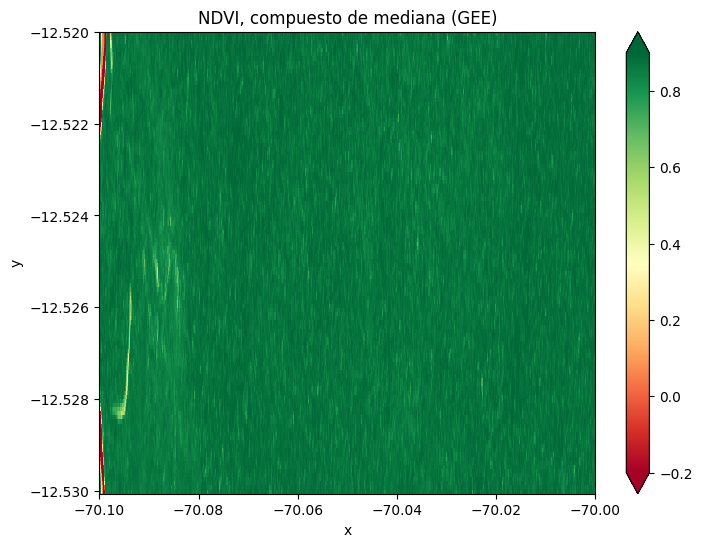

CPU times: user 372 ms, sys: 1.72 ms, total: 373 ms
Wall time: 3.77 s


In [ ]:
%%time
# Opcional. Compuesto de mediana de todas las escenas filtradas, sin elegir una sola escena
ndvi_comp_img = coleccion.median().normalizedDifference(["B8", "B4"]).rename("NDVI") #se le calcula la mediana
ndvi_comp = descargar(ndvi_comp_img, "ndvi_compuesto_gee.tif", 10)

ndvi_comp.plot(cmap="RdYlGn", vmin=-0.2, vmax=0.9, figsize=(8, 6))
plt.title("NDVI, compuesto de mediana (GEE)")
plt.show()

## Bloque 4. Integración

In [ ]:
# Opción local. Misma lógica que en el notebook de STAC
wc_alineado = wc.rio.reproject_match(ndvi, resampling=Resampling.nearest) #con esta función se reproyectan segun las coordenadas
wc_alineado = wc_alineado.where(wc_alineado.isin(list(CLASES))) #where va a aplicar una función en donde solo cumpla con cierta condición

por_clase = ndvi.groupby(wc_alineado.rename("clase")).mean() #para calcular el valor medio del indice para cada cobertura; el rename le da el nombre de "clase" al grupo
for cod, v in zip(por_clase["clase"].values, por_clase.values):
    print(f"{CLASES[int(cod)]:<20} NDVI medio {v:5.2f}")

Árboles              NDVI medio  0.77
Arbustos             NDVI medio  0.69
Pastizal             NDVI medio  0.55
Cultivos             NDVI medio  0.61
Urbano               NDVI medio  0.25
Suelo desnudo/ralo   NDVI medio  0.22
Agua                 NDVI medio -0.09
Humedal herbáceo     NDVI medio  0.59


In [ ]:
%%time
# Opción en el servidor. Solo viajan los resultados, no los píxeles
stats = (
    ndvi_img.addBands(wc_img)
    .reduceRegion(
        reducer=ee.Reducer.mean().group(groupField=1, groupName="clase"),
        geometry=region,
        scale=10,
        maxPixels=1e9,
    )
    .getInfo()
)
for g in stats["groups"]:
    print(f"{CLASES[int(g['clase'])]:<20} NDVI medio {g['mean']:5.2f}")

Árboles              NDVI medio  0.90
Pastizal             NDVI medio  0.11
Suelo desnudo/ralo   NDVI medio  0.08
Agua                 NDVI medio -0.22
CPU times: user 8.5 ms, sys: 106 µs, total: 8.6 ms
Wall time: 1.41 s
